# FarmTech Solutions — Fase 6: O despertar da Rede Neural

**Grupo 38 — Graduação ON em Inteligência Artificial — FIAP**

| Integrante | RM |
|---|---|
| Matheus de França Fantini | RM574078 |
| Maykon Eduardo Pereira de Sousa | RM574011 |
| Samantha Silva Farias | RM574120 |

## Contexto

A FarmTech Solutions expandiu seus serviços de IA para além do agronegócio e passou a atuar com **visão computacional**. Um cliente
do setor agropecuário quer entender, na prática, o que um sistema de visão computacional consegue fazer. Para demonstrar, montamos um
detector que diferencia dois objetos bem distintos do dia a dia de uma fazenda:

- **Objeto A — `vaca`** (rebanho, pastagem)
- **Objeto B — `laranja`** (fruta da produção citrícola)

## Roteiro do notebook

1. Preparação do ambiente (Google Drive + YOLOv5)
2. Dataset: organização, rotulação no Make Sense e conferência
3. **Entrega 1** — YOLOv5 customizado: treino com **30** e **60** épocas
4. **Entrega 1** — Validação, teste e imagens processadas
5. **Entrega 2** — YOLOv5 tradicional (pesos COCO, sem customização)
6. **Entrega 2** — CNN treinada do zero (classificação)
7. **Entrega 2** — Comparação crítica das três abordagens
8. Conclusões, pontos fortes e limitações

## 1. Preparação do ambiente

O notebook foi feito para rodar no **Google Colab com GPU** (`Ambiente de execução > Alterar o tipo de ambiente > GPU T4`).
Os dados ficam no Google Drive, na pasta `MyDrive/FarmTech_Fase6`, com a seguinte estrutura:

```
FarmTech_Fase6/
├── dataset/
│   └── images/
│       ├── train/   # 32 vacas + 32 laranjas
│       ├── val/     #  4 vacas +  4 laranjas
│       └── test/    #  4 vacas +  4 laranjas
└── rotulos_makesense.zip   # exportação YOLO do Make Sense (todas as 80 imagens)
```

As pastas `dataset/labels/*` e `runs/*` são criadas pelo próprio notebook.

In [4]:
import os, sys, time, shutil, zipfile                       # utilitários de sistema, tempo e arquivos
from pathlib import Path                                     # manipulação de caminhos

EM_COLAB = 'google.colab' in sys.modules                     # detecta se estamos no Colab
if EM_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')                            # conecta o Google Drive
    BASE = Path('/content/drive/MyDrive/FarmTech_Fase6')     # pasta do projeto no Drive
    WORK = Path('/content')                                  # disco local do Colab (mais rápido que o Drive)
else:
    BASE = WORK = Path.cwd()                                 # execução local: tudo na pasta atual

DATASET_DRIVE = BASE / 'dataset'                             # imagens organizadas no Drive
RUNS = BASE / 'runs'                                         # resultados (treinos, validações, detecções) salvos no Drive
YOLO_DIR = WORK / 'yolov5'                                   # código do YOLOv5
CLASSES = ['vaca', 'laranja']                                # índice 0 = vaca, 1 = laranja (mesma ordem do Make Sense)
print('Projeto em:', BASE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projeto em: /content/drive/MyDrive/FarmTech_Fase6


In [5]:
# Clona o repositório oficial do YOLOv5 e instala as dependências
if not YOLO_DIR.exists():
    !git clone -q https://github.com/ultralytics/yolov5 {YOLO_DIR}
!pip install -q -r {YOLO_DIR}/requirements.txt

import torch
print('PyTorch', torch.__version__, '| GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'não disponível')

PyTorch 2.11.0+cu130 | GPU: Tesla T4


## 2. Dataset

### 2.1 Origem e divisão das imagens

São **80 imagens** reais: 40 de vacas e 40 de laranjas. Cada classe foi dividida em **32 imagens de treino, 4 de validação e 4 de teste**.
Escolhemos fotos em que o objeto aparece com destaque, com fundos variados (pasto, curral, mesa, árvore, feira), para o modelo
aprender o objeto e não o cenário. Os arquivos seguem o padrão `classe_NN.jpg` (ex.: `vaca_07.jpg`).

### 2.2 Rotulação no Make Sense

1. Acessamos [makesense.ai](https://www.makesense.ai) → *Get Started* → carregamos as 80 imagens → *Object Detection*.
2. Para agilizar, ativamos a rotulação assistida (*Actions → Run AI locally → COCO SSD*): o Make Sense sugere caixas com os
   nomes do COCO, então a lista de rótulos ficou **nesta ordem**: `cow` (classe 0 = vaca) e `orange` (classe 1 = laranja).
3. Revisamos imagem a imagem: ajustamos as caixas sugeridas, desenhamos as que faltavam e apagamos sugestões de outros
   objetos (ex.: bananas e maçãs ao lado das laranjas).
4. *Actions → Export Annotations → YOLO format*: o Make Sense gera um `.zip` com um `.txt` por imagem
   (`classe x_centro y_centro largura altura`, valores normalizados de 0 a 1).
5. Salvamos o zip no Drive como `FarmTech_Fase6/rotulos_makesense.zip`.

A célula abaixo distribui cada `.txt` para a pasta `labels/` do mesmo split da imagem, no formato que o YOLOv5 espera,
mantendo apenas as classes 0 e 1 (rótulos extras criados pela IA do Make Sense, como `banana`, são descartados).

In [6]:
# Distribui os rótulos exportados do Make Sense para dataset/labels/{train,val,test}
with zipfile.ZipFile(BASE / 'rotulos_makesense.zip') as z:
    rotulos = {Path(n).stem: z.read(n).decode() for n in z.namelist() if n.endswith('.txt')}

imagens = sorted(p.stem for p in DATASET_DRIVE.glob('images/*/*.jpg'))
sem_rotulo = [s for s in imagens if s not in rotulos]          # o Make Sense não exporta .txt de imagem sem caixa
assert not sem_rotulo, f'Imagens sem nenhuma caixa no Make Sense: {sem_rotulo}'

for split in ['train', 'val', 'test']:
    (DATASET_DRIVE / 'labels' / split).mkdir(parents=True, exist_ok=True)
    for img in (DATASET_DRIVE / 'images' / split).glob('*.jpg'):
        linhas = [l for l in rotulos[img.stem].splitlines() if l.split() and l.split()[0] in ('0', '1')]  # só vaca/laranja
        (DATASET_DRIVE / 'labels' / split / f'{img.stem}.txt').write_text('\n'.join(linhas) + '\n')

# No Colab copiamos o dataset para o disco local: o treino lê as imagens muito mais rápido que direto do Drive
DATA_DIR = WORK / 'dataset'
if DATA_DIR != DATASET_DRIVE:
    shutil.copytree(DATASET_DRIVE, DATA_DIR, dirs_exist_ok=True)
print(len(rotulos), 'arquivos de rótulo distribuídos')

80 arquivos de rótulo distribuídos


In [7]:
import pandas as pd                                           # tabelas
import matplotlib.pyplot as plt                               # gráficos
from PIL import Image                                         # leitura de imagens

# Confere o dataset: quantidade de imagens e de caixas por split/classe, e se o rótulo bate com o nome do arquivo
linhas = []
for split in ['train', 'val', 'test']:
    for img in sorted((DATA_DIR / 'images' / split).glob('*.jpg')):
        classe_arquivo = img.stem.split('_')[0]                                  # 'vaca' ou 'laranja' pelo nome
        caixas = [l.split() for l in (DATA_DIR / 'labels' / split / f'{img.stem}.txt').read_text().splitlines() if l.strip()]
        ids = {CLASSES[int(c[0])] for c in caixas}                               # classes rotuladas na imagem
        assert ids == {classe_arquivo}, f'{img.name}: rótulo {ids} não confere (ordem dos rótulos no Make Sense?)'
        linhas.append({'split': split, 'classe': classe_arquivo, 'caixas': len(caixas)})

resumo = pd.DataFrame(linhas).groupby(['split', 'classe']).agg(imagens=('caixas', 'size'), caixas=('caixas', 'sum'))
resumo

imagens  caixas
split classe                  
test  laranja        4       4
      vaca           4       6
train laranja       32      41
      vaca          32      45
val   laranja        4       6
      vaca           4       6

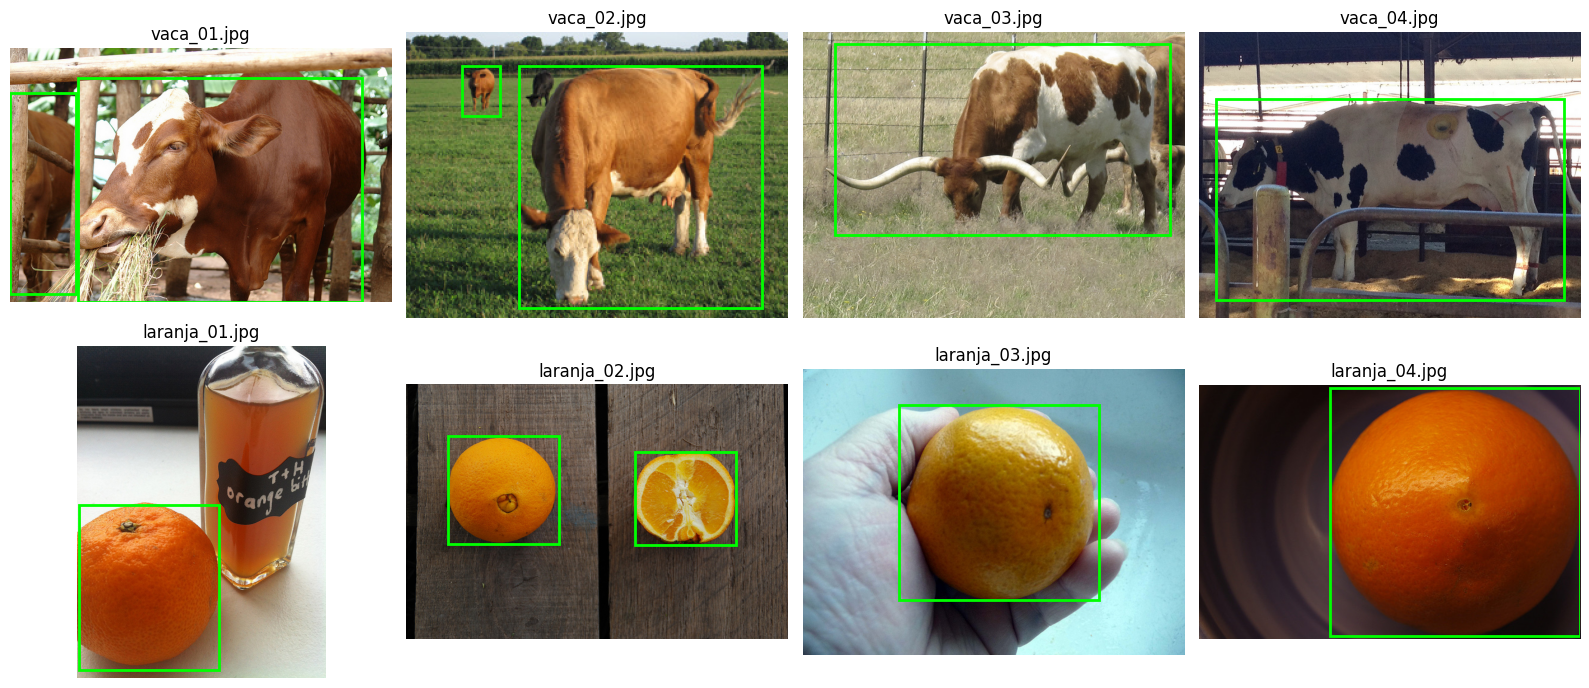

In [8]:
# Amostra visual do dataset de treino com as caixas rotuladas no Make Sense
from matplotlib.patches import Rectangle

amostra = sorted((DATA_DIR / 'images' / 'train').glob('vaca_*.jpg'))[:4] + sorted((DATA_DIR / 'images' / 'train').glob('laranja_*.jpg'))[:4]
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, img in zip(axs.flat, amostra):
    im = Image.open(img); w, h = im.size
    ax.imshow(im); ax.set_title(img.name); ax.axis('off')
    for linha in (DATA_DIR / 'labels' / 'train' / f'{img.stem}.txt').read_text().split('\n'):
        if not linha.strip():
            continue
        c, xc, yc, bw, bh = map(float, linha.split())                     # formato YOLO normalizado
        ax.add_patch(Rectangle(((xc - bw / 2) * w, (yc - bh / 2) * h), bw * w, bh * h, fill=False, color='lime', lw=2))
plt.tight_layout(); plt.show()

In [9]:
# Arquivo de configuração do dataset para o YOLOv5
DATA_YAML = WORK / 'farmtech.yaml'
DATA_YAML.write_text(f'''path: {DATA_DIR}
train: images/train
val: images/val
test: images/test
names:
  0: vaca
  1: laranja
''')
print(DATA_YAML.read_text())

path: /content/dataset
train: images/train
val: images/val
test: images/test
names:
  0: vaca
  1: laranja



## 3. Entrega 1 — Treinamento do YOLOv5 customizado

Partimos dos pesos `yolov5s.pt` (versão *small*, pré-treinada no COCO) e ajustamos a rede para as nossas duas classes (*transfer learning*).
Para medir o efeito da quantidade de épocas, fazemos **duas simulações idênticas, mudando só o número de épocas: 30 e 60**.

Parâmetros: imagem 640 px, *batch* 16, *seed* 42. A cada época o YOLOv5 avalia o modelo no conjunto de **validação** e guarda o
melhor peso em `weights/best.pt`.

In [10]:
tempo_treino = {}                                             # tempo de treino (s) de cada simulação

# Simulação 1: 30 épocas
t0 = time.perf_counter()
!cd {YOLO_DIR} && python train.py --img 640 --batch 16 --epochs 30 --data {DATA_YAML} --weights yolov5s.pt --project {RUNS}/train --name e30 --exist-ok --seed 42 --workers 2
tempo_treino[30] = time.perf_counter() - t0

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791941377.774706    3210 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=/content/farmtech.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=30, batch_size=16, imgsz=640, re

In [11]:
# Simulação 2: 60 épocas
t0 = time.perf_counter()
!cd {YOLO_DIR} && python train.py --img 640 --batch 16 --epochs 60 --data {DATA_YAML} --weights yolov5s.pt --project {RUNS}/train --name e60 --exist-ok --seed 42 --workers 2
tempo_treino[60] = time.perf_counter() - t0
print({k: f'{v:.0f} s' for k, v in tempo_treino.items()})

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791941510.276037    3923 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=/content/farmtech.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=60, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=2, project=/content

### 3.1 Curvas de treino: 30 × 60 épocas

O YOLOv5 grava em `results.csv` as perdas (*loss*) e as métricas de validação de cada época:

- **box_loss**: erro na posição e no tamanho da caixa;
- **obj_loss**: erro em dizer se existe objeto naquele ponto;
- **cls_loss**: erro na classe (vaca × laranja);
- **precision / recall / mAP@0.5**: qualidade das detecções no conjunto de validação.

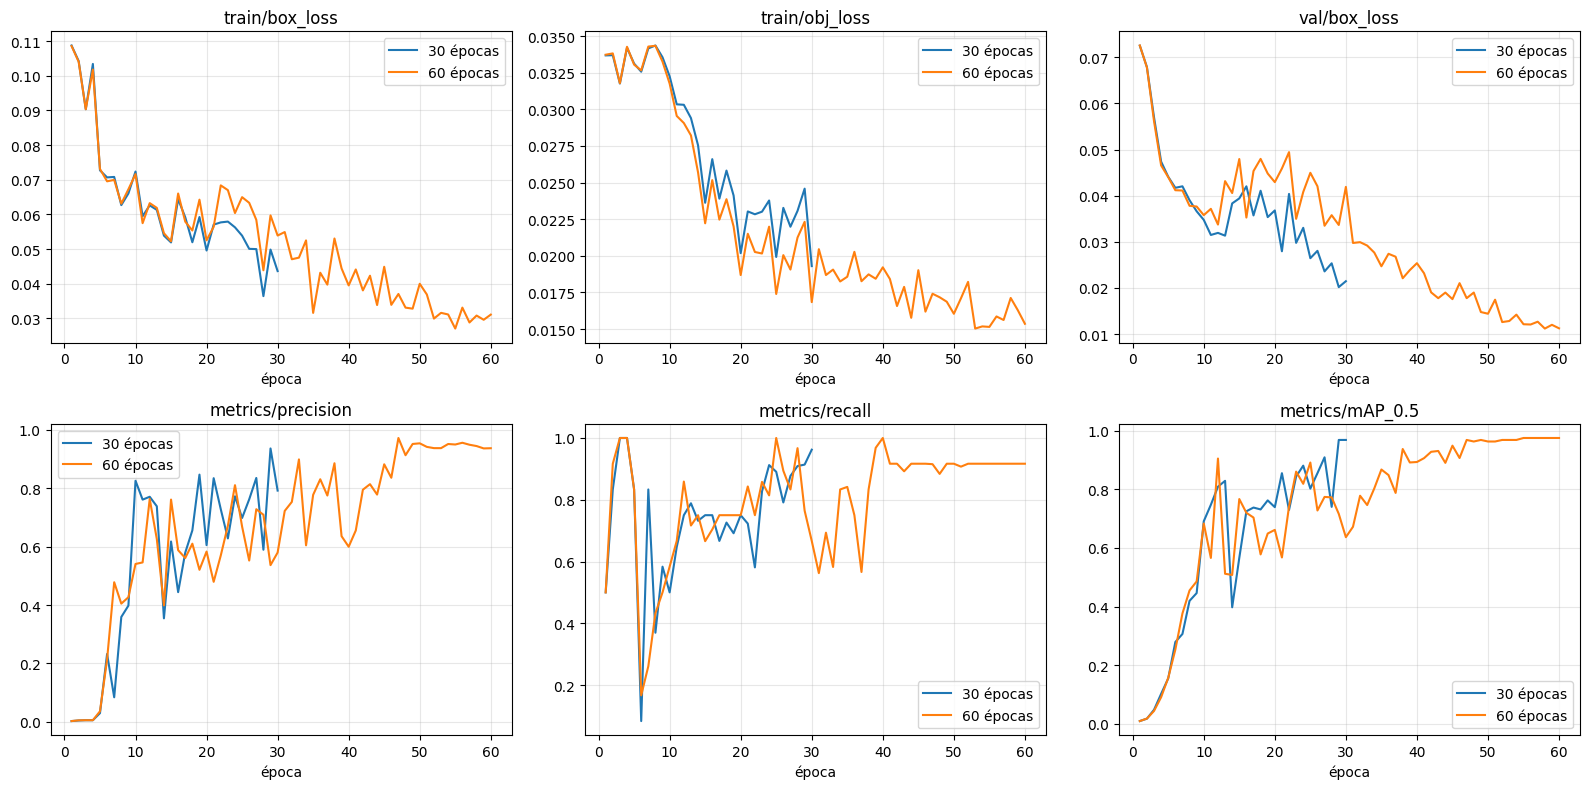

,30 épocas,60 épocas
train/box_loss,0.044,0.031
train/obj_loss,0.019,0.015
val/box_loss,0.021,0.011
metrics/precision,0.792,0.937
metrics/recall,0.962,0.917
metrics/mAP_0.5,0.968,0.975


In [12]:
# Lê os históricos de treino e plota as duas simulações lado a lado
hist = {}
for ep in [30, 60]:
    df = pd.read_csv(RUNS / 'train' / f'e{ep}' / 'results.csv')
    df.columns = df.columns.str.strip()                       # o YOLOv5 grava os nomes com espaços
    hist[ep] = df

metricas = ['train/box_loss', 'train/obj_loss', 'val/box_loss', 'metrics/precision', 'metrics/recall', 'metrics/mAP_0.5']
fig, axs = plt.subplots(2, 3, figsize=(16, 8))
for ax, m in zip(axs.flat, metricas):
    for ep, df in hist.items():
        ax.plot(df['epoch'] + 1, df[m], label=f'{ep} épocas')
    ax.set_title(m); ax.set_xlabel('época'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# Métricas da última época de cada simulação
pd.DataFrame({f'{ep} épocas': df.iloc[-1][metricas] for ep, df in hist.items()}).round(3)

## 4. Entrega 1 — Validação e teste

Usamos o melhor peso (`best.pt`) de cada simulação para medir o desempenho em dois conjuntos:

- **validação** (8 imagens): usado durante o treino para escolher o `best.pt`;
- **teste** (8 imagens): nunca visto pelo modelo, é a medida mais honesta de generalização.

A função `val.run` do YOLOv5 devolve precisão, *recall*, mAP@0.5, mAP@0.5:0.95 e o tempo médio de inferência por imagem.

In [24]:
sys.path.insert(0, str(YOLO_DIR))
import val as yolo_val                                        # módulo de validação do YOLOv5
%matplotlib inline

def avaliar_yolo(pesos, data, task, nome):
    """Roda a validação do YOLOv5 e devolve as métricas principais."""
    (p, r, map50, map5095, *_), _, tempos = yolo_val.run(data=str(data), weights=str(pesos), task=task, imgsz=640,
                                                          project=str(RUNS / 'val'), name=nome, exist_ok=True)
    return {'precisão': p, 'recall': r, 'mAP@0.5': map50, 'mAP@0.5:0.95': map5095, 'inferência (ms/img)': tempos[1]}

metricas_custom = {}
for ep in [30, 60]:
    pesos = RUNS / 'train' / f'e{ep}' / 'weights' / 'best.pt'
    for task in ['val', 'test']:
        metricas_custom[(f'YOLO custom {ep} ép.', task)] = avaliar_yolo(pesos, DATA_YAML, task, f'e{ep}_{task}')

tab_custom = pd.DataFrame(metricas_custom).T.round(3)
tab_custom

YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /content/dataset/labels/val.cache... 8 images, 0 backgrounds, 0 corrupt
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 3.6it/s 0.3s
                   all          8         12      0.792      0.963      0.968      0.714
                  vaca          8          6      0.935          1      0.995      0.729
               laranja          8          6      0.648      0.926      0.942        0.7
Speed: 0.6ms pre-process, 5.0ms inference, 3.3ms NMS per image at shape (32, 3, 640, 640)
Results saved to /content/drive/MyDrive/FarmTech_Fase6/runs/val/e30_val
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFL

precisão  recall  mAP@0.5  mAP@0.5:0.95  \
YOLO custom 30 ép. val      0.792   0.963    0.968         0.714   
                   test     0.686   0.963    0.923         0.647   
YOLO custom 60 ép. val      0.936   0.917    0.975         0.844   
                   test     0.688   1.000    0.878         0.736   

                         inferência (ms/img)  
YOLO custom 30 ép. val                 4.965  
                   test                5.637  
YOLO custom 60 ép. val                 4.575  
                   test                5.929

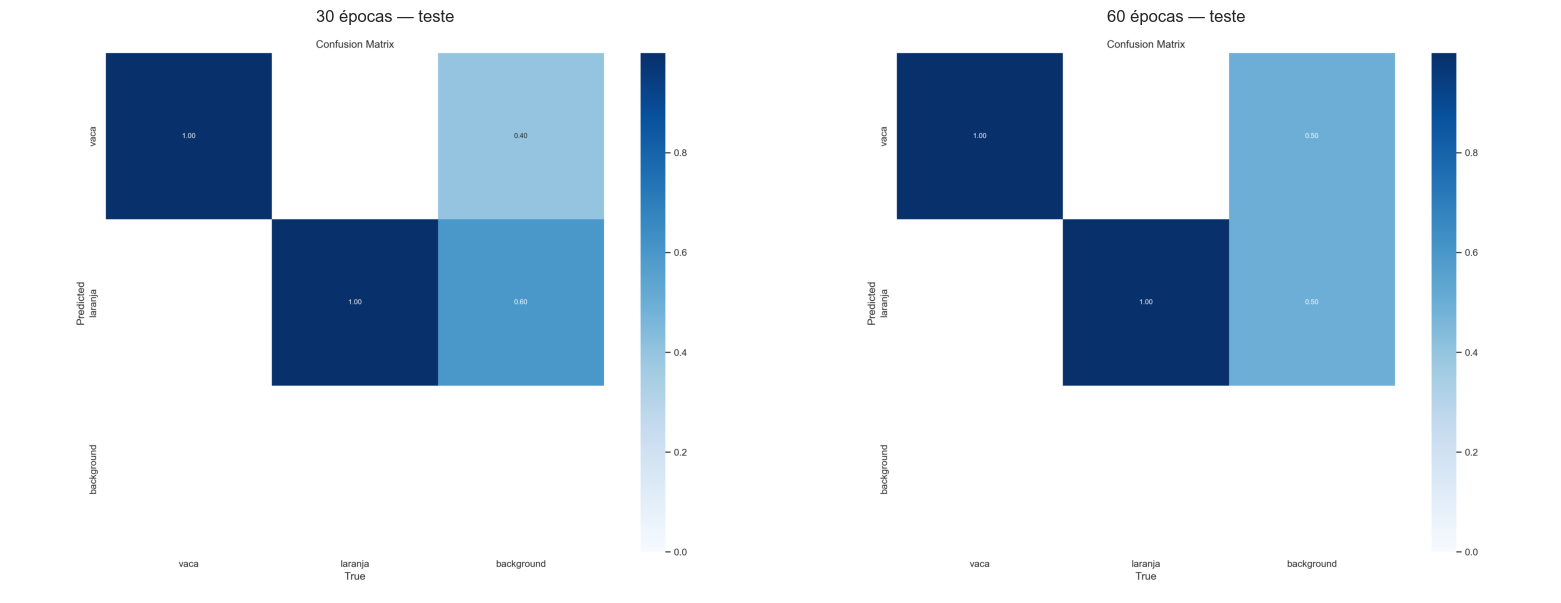

In [25]:
# Matrizes de confusão no conjunto de teste geradas pelo YOLOv5
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
for ax, ep in zip(axs, [30, 60]):
    ax.imshow(Image.open(RUNS / 'val' / f'e{ep}_test' / 'confusion_matrix.png')); ax.set_title(f'{ep} épocas — teste'); ax.axis('off')
plt.tight_layout(); plt.show()

### 4.1 Imagens de teste processadas

Rodamos o `detect.py` do YOLOv5 nas 8 imagens de teste com o `best.pt` de cada simulação. As imagens com as caixas e a confiança
ficam salvas em `runs/detect/e30` e `runs/detect/e60`. São esses prints que apresentamos ao cliente.

detect: weights=['/content/drive/MyDrive/FarmTech_Fase6/runs/train/e30/weights/best.pt'], source=/content/dataset/images/test, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=/content/drive/MyDrive/FarmTech_Fase6/runs/detect, name=e30, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/8 /content/dataset/images/test/laranja_37.jpg: 640x480 1 laranja, 26.7ms
image 2/8 /content/dataset/images/test/laranja_38.jpg: 448x640 2 laranjas, 27.5ms
image 3/8 /content/dataset/images/test/laranja_39.jpg: 448x640 1 laranja, 8.8ms
im

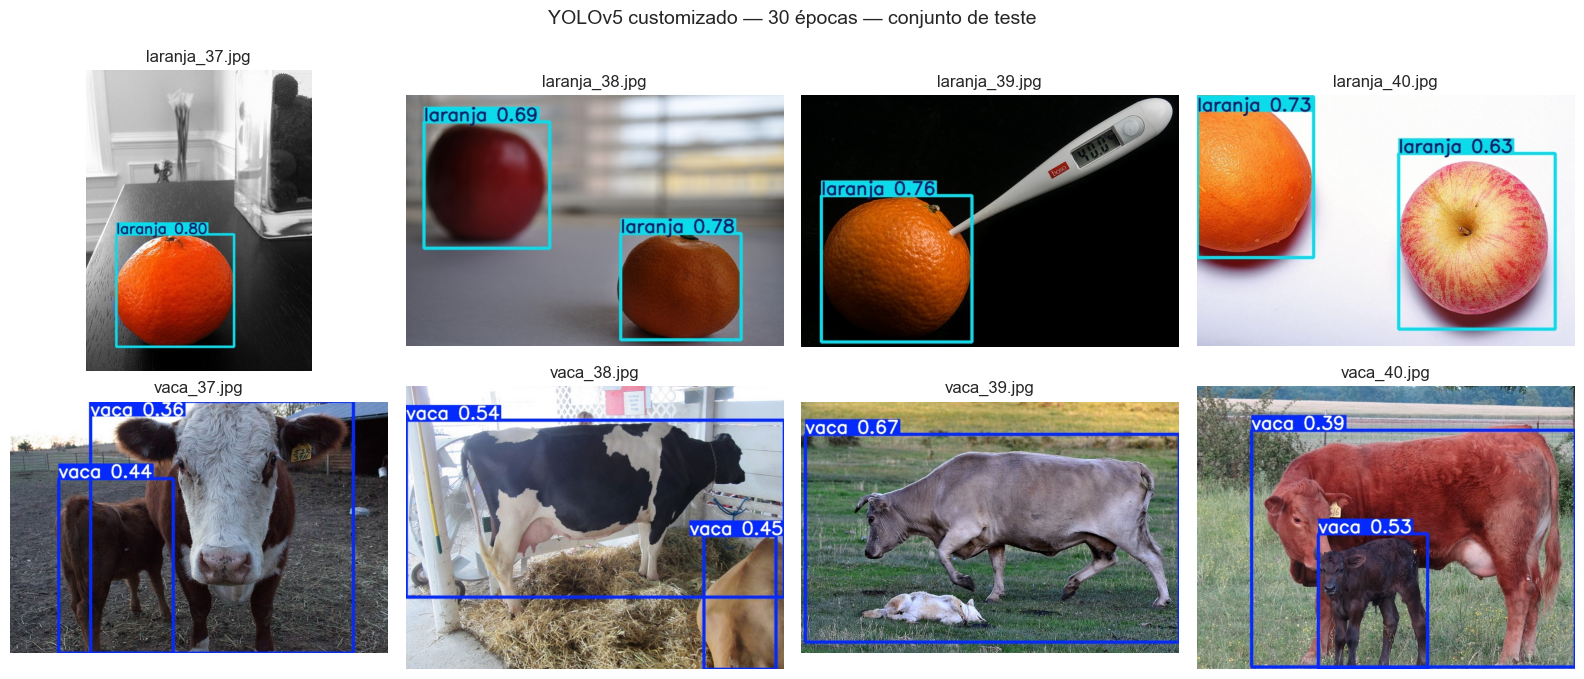

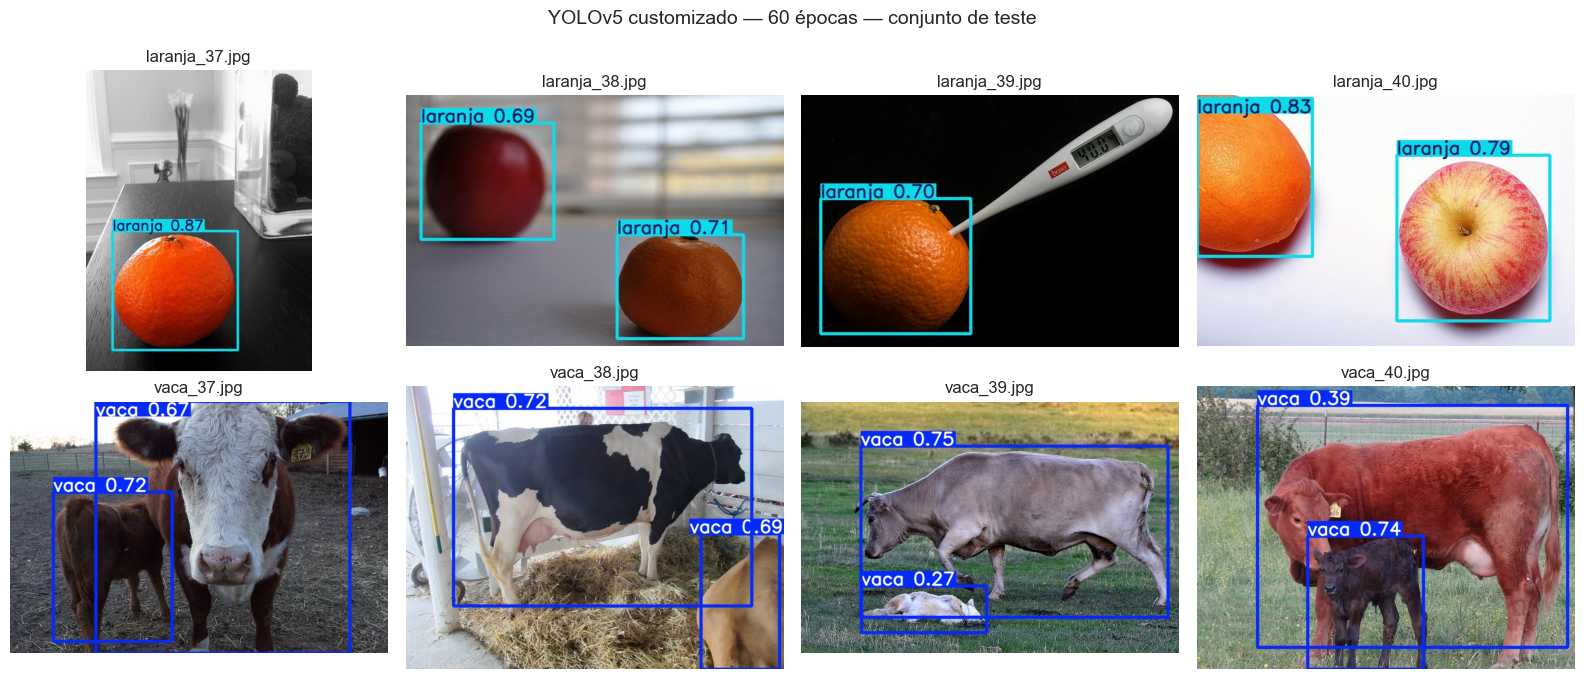

In [26]:
for ep in [30, 60]:
    !cd {YOLO_DIR} && python detect.py --weights {RUNS}/train/e{ep}/weights/best.pt --source {DATA_DIR}/images/test --project {RUNS}/detect --name e{ep} --exist-ok

def mostrar_grade(pasta, titulo):
    """Exibe as 8 imagens processadas de uma pasta em grade 2x4."""
    imgs = sorted(Path(pasta).glob('*.jpg'))
    fig, axs = plt.subplots(2, 4, figsize=(16, 7))
    for ax, img in zip(axs.flat, imgs):
        ax.imshow(Image.open(img)); ax.set_title(img.name); ax.axis('off')
    fig.suptitle(titulo, fontsize=14); plt.tight_layout(); plt.show()

for ep in [30, 60]:
    mostrar_grade(RUNS / 'detect' / f'e{ep}', f'YOLOv5 customizado — {ep} épocas — conjunto de teste')

### 4.2 Análise da Entrega 1

**Treino (30 × 60 épocas).** Os dois treinos partiram dos mesmos pesos e usaram os mesmos parâmetros; só o número de épocas mudou.
O treino de 60 épocas levou cerca de 189 s, contra 145 s do de 30 (os dois tempos incluem a preparação do ambiente; o laço de treino em si levou
~1,1 min e ~2,2 min). Com o dobro de épocas, todas as perdas caíram mais: a `val/box_loss` foi de 0,021 para 0,011, ou seja, as caixas ficaram
mais justas em volta dos objetos.

**Validação (8 imagens, 12 caixas).** As duas versões já acertam praticamente todos os objetos (mAP@0.5 de 0,968 e 0,975), mas a de 60 épocas é
claramente melhor na **qualidade da caixa**: mAP@0.5:0.95 subiu de 0,714 para 0,844 e a precisão de 0,79 para 0,94 (menos caixas sobrando).
Com 30 épocas o modelo ainda estava aprendendo; com 60 ele estabiliza.

**Teste (8 imagens nunca vistas, 10 caixas).** Os dois modelos acertaram a classe de **todas as 8 imagens** e encontraram praticamente todos os
objetos (recall 0,96 e 1,00). A diferença está nos detalhes:

| Teste | 30 épocas | 60 épocas |
|---|---|---|
| Precisão | 0,686 | 0,688 |
| Recall | 0,963 | 1,000 |
| mAP@0.5 | 0,923 | 0,878 |
| mAP@0.5:0.95 | 0,647 | **0,736** |

- Com 60 épocas a localização melhora bastante (mAP@0.5:0.95 +0,09), confirmando o que vimos na validação.
- A precisão ficou em ~0,69 nos dois porque **os dois modelos marcaram maçãs como laranja** (`laranja_38` e `laranja_40`, nas imagens acima):
  fruta redonda, do mesmo tamanho e com brilho parecido. No nosso treino só existiam exemplos positivos de laranja — o modelo nunca aprendeu
  o que *não* é laranja. É a principal limitação encontrada, e se resolve adicionando ao treino fotos com maçãs, tomates e outras frutas sem rótulo.
- Com 60 épocas o modelo também encontrou o **bezerro deitado** em `vaca_39` (confiança 0,27), que o de 30 épocas não detectou, e as
  confianças das vacas subiram de 0,36–0,67 para 0,39–0,75. Como esse bezerro não foi rotulado, a nova caixa conta como erro no teste —
  por isso o mAP@0.5 caiu um pouco (0,92 → 0,88) mesmo com o modelo melhor. Com apenas 10 caixas no teste, **uma** caixa a mais ou a menos
  move essas métricas em vários pontos.
- As vacas são detectadas com mais segurança que as laranjas (precisão por classe de 0,75–0,99 para vaca contra 0,53–0,88 para laranja, somando validação e teste): são objetos grandes e com formato
  muito característico, enquanto a laranja se confunde com outras frutas redondas.

**Escolha para o cliente:** o modelo de **60 épocas**. Ele acerta todas as imagens de teste, encontra todos os objetos e desenha caixas mais
precisas; o custo é só cerca de 1 minuto a mais de treino. Os prints acima mostram as detecções com a confiança de cada caixa.

## 5. Entrega 2 — YOLOv5 tradicional (sem customização)

Aqui usamos o `yolov5s.pt` **original**, treinado no dataset COCO (80 classes), sem nenhum treino adicional. O COCO já possui as
classes `cow` (id 19) e `orange` (id 49), então medimos o que o modelo "de prateleira" entrega para o nosso problema.

Para calcular as mesmas métricas (mAP, precisão, *recall*) no nosso conjunto de teste, criamos uma cópia dos rótulos de teste
convertendo os ids: `vaca 0 → 19` e `laranja 1 → 49`.

In [27]:
import yaml

PESOS_COCO = YOLO_DIR / 'yolov5s.pt'                          # baixado automaticamente no primeiro treino
COCO_IDS = {0: 19, 1: 49}                                     # vaca -> cow, laranja -> orange

# Cópia do conjunto de teste com rótulos nos ids do COCO
coco_dir = WORK / 'teste_coco'
(coco_dir / 'labels' / 'test').mkdir(parents=True, exist_ok=True)
shutil.copytree(DATA_DIR / 'images' / 'test', coco_dir / 'images' / 'test', dirs_exist_ok=True)
for txt in (DATA_DIR / 'labels' / 'test').glob('*.txt'):
    linhas = [l.split() for l in txt.read_text().splitlines() if l.strip()]
    (coco_dir / 'labels' / 'test' / txt.name).write_text('\n'.join(' '.join([str(COCO_IDS[int(l[0])])] + l[1:]) for l in linhas))

nomes_coco = yaml.safe_load((YOLO_DIR / 'data' / 'coco.yaml').read_text())['names']
COCO_YAML = WORK / 'teste_coco.yaml'
COCO_YAML.write_text(yaml.dump({'path': str(coco_dir), 'train': 'images/test', 'val': 'images/test', 'test': 'images/test', 'names': nomes_coco}))

metricas_coco = {('YOLO tradicional (COCO)', 'test'): avaliar_yolo(PESOS_COCO, COCO_YAML, 'test', 'coco_test')}
pd.DataFrame(metricas_coco).T.round(3)

YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
test: Scanning /content/teste_coco/labels/test... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 615.1it/s 0.0s
test: New cache created: /content/teste_coco/labels/test.cache
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 3.0it/s 0.3s
                   all          8         10      0.909          1      0.936      0.866
Speed: 0.4ms pre-process, 5.9ms inference, 1.6ms NMS per image at shape (32, 3, 640, 640)
Results saved to /content/drive/MyDrive/FarmTech_Fase6/runs/val/coco_test


,,precisão,recall,mAP@0.5,mAP@0.5:0.95,inferência (ms/img)
YOLO tradicional (COCO),test,0.909,1.0,0.936,0.866,5.898


detect: weights=['/content/yolov5/yolov5s.pt'], source=/content/dataset/images/test, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=[19, 49], agnostic_nms=False, augment=False, update=False, project=/content/drive/MyDrive/FarmTech_Fase6/runs/detect, name=coco, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
image 1/8 /content/dataset/images/test/laranja_37.jpg: 640x480 1 orange, 28.0ms
image 2/8 /content/dataset/images/test/laranja_38.jpg: 448x640 1 orange, 28.5ms
image 3/8 /content/dataset/images/test/laranja_39.jpg: 448x640 1 orange, 8.7ms
image 4/8 /content/dataset/images/test/l

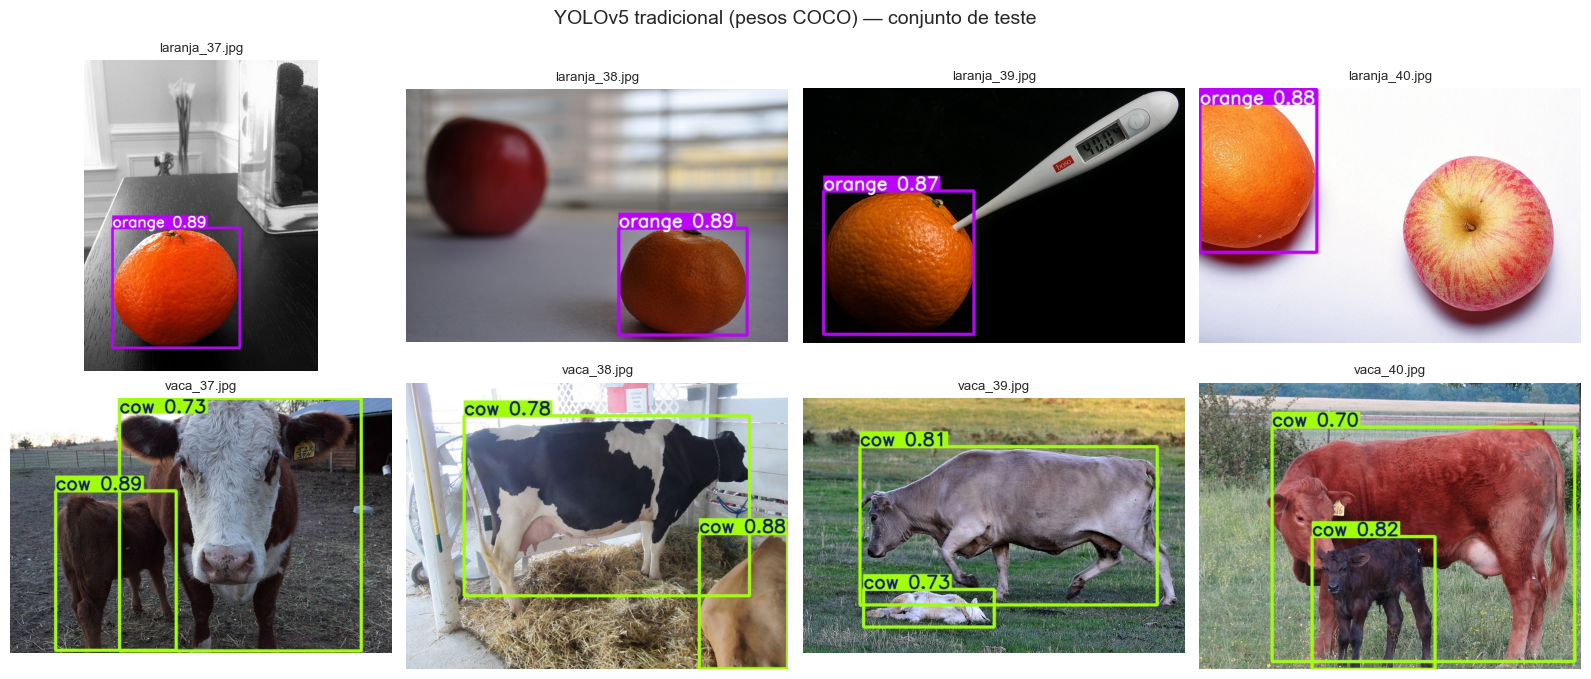

In [28]:
# Detecções do YOLOv5 tradicional nas imagens de teste (somente as classes cow e orange)
!cd {YOLO_DIR} && python detect.py --weights {PESOS_COCO} --source {DATA_DIR}/images/test --classes 19 49 --project {RUNS}/detect --name coco --exist-ok
mostrar_grade(RUNS / 'detect' / 'coco', 'YOLOv5 tradicional (pesos COCO) — conjunto de teste')

## 6. Entrega 2 — CNN treinada do zero

A terceira abordagem é uma **rede convolucional de classificação**, criada e treinada do zero com Keras/TensorFlow. Ela não localiza
o objeto: só responde se a imagem é de **vaca** ou de **laranja**.

- Entrada: imagem redimensionada para 128×128 px;
- *Data augmentation* (espelhamento, rotação e zoom aleatórios) para compensar o dataset pequeno;
- 3 blocos `Conv2D + MaxPooling` (16, 32 e 64 filtros) → `GlobalAveragePooling` → `Dropout` → saída sigmoide;
- `EarlyStopping` na perda de validação, mantendo os melhores pesos.

Usamos os mesmos splits (32/4/4 por classe) e as mesmas imagens das abordagens YOLO.

In [29]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

TAM = 128                                                     # lado da imagem de entrada da CNN

def carregar_split(split):
    """Carrega as imagens de um split como array (N, TAM, TAM, 3) e o rótulo pelo nome do arquivo (0 vaca, 1 laranja)."""
    caminhos = sorted((DATA_DIR / 'images' / split).glob('*.jpg'))
    X = np.stack([np.asarray(Image.open(p).convert('RGB').resize((TAM, TAM)), dtype='float32') for p in caminhos])
    y = np.array([CLASSES.index(p.stem.split('_')[0]) for p in caminhos])
    return X, y, caminhos

(X_tr, y_tr, _), (X_va, y_va, _), (X_te, y_te, cam_te) = map(carregar_split, ['train', 'val', 'test'])
print('treino', X_tr.shape, '| validação', X_va.shape, '| teste', X_te.shape)

treino (64, 128, 128, 3) | validação (8, 128, 128, 3) | teste (8, 128, 128, 3)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,649 (92.38 KB)

 Trainable params: 23,649 (92.38 KB)

 Non-trainable params: 0 (0.00 B)

Treino: 45 épocas em 9 s


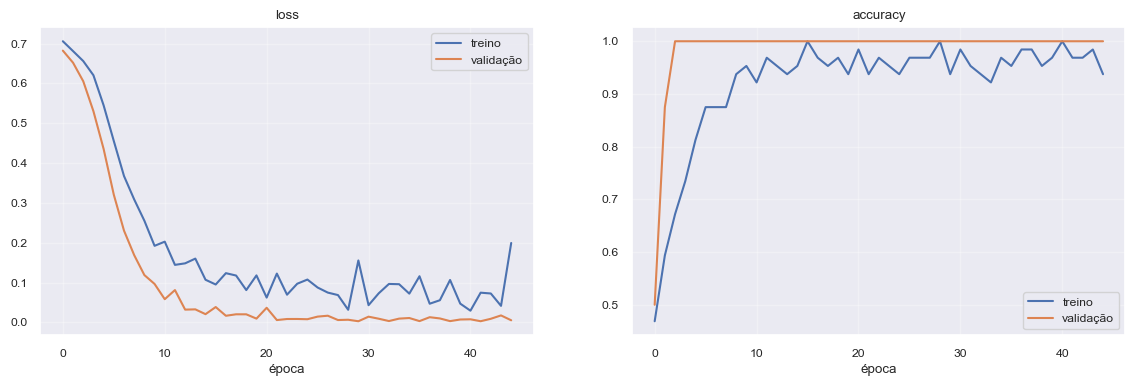

In [30]:
keras.utils.set_random_seed(42)                               # reprodutibilidade

cnn = keras.Sequential([
    layers.Input((TAM, TAM, 3)),
    layers.RandomFlip('horizontal'),                          # data augmentation (só atua no treino)
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2),
    layers.Rescaling(1 / 255),                                # pixels de 0-255 para 0-1
    layers.Conv2D(16, 3, activation='relu', padding='same'), layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation='relu', padding='same'), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu', padding='same'), layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),                          # resume cada mapa de características em 1 valor
    layers.Dropout(0.3),                                      # reduz overfitting
    layers.Dense(1, activation='sigmoid'),                    # probabilidade de ser laranja
])
cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])
cnn.summary()

t0 = time.perf_counter()
historico = cnn.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=100, batch_size=8, verbose=0,
                    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)])
tempo_treino['CNN'] = time.perf_counter() - t0
print(f"Treino: {len(historico.history['loss'])} épocas em {tempo_treino['CNN']:.0f} s")

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for ax, m in zip(axs, ['loss', 'accuracy']):
    ax.plot(historico.history[m], label='treino'); ax.plot(historico.history[f'val_{m}'], label='validação')
    ax.set_title(m); ax.set_xlabel('época'); ax.legend(); ax.grid(alpha=.3)
plt.show()

Acurácia da CNN no teste: 0.75


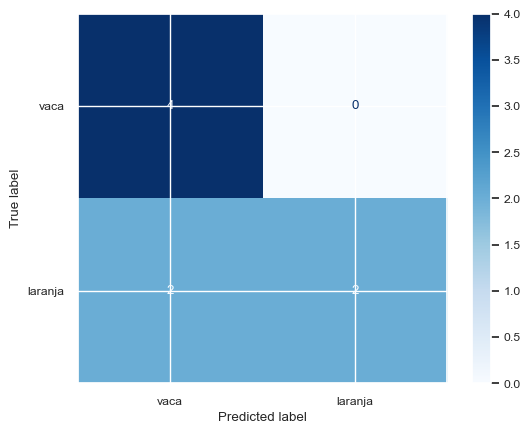

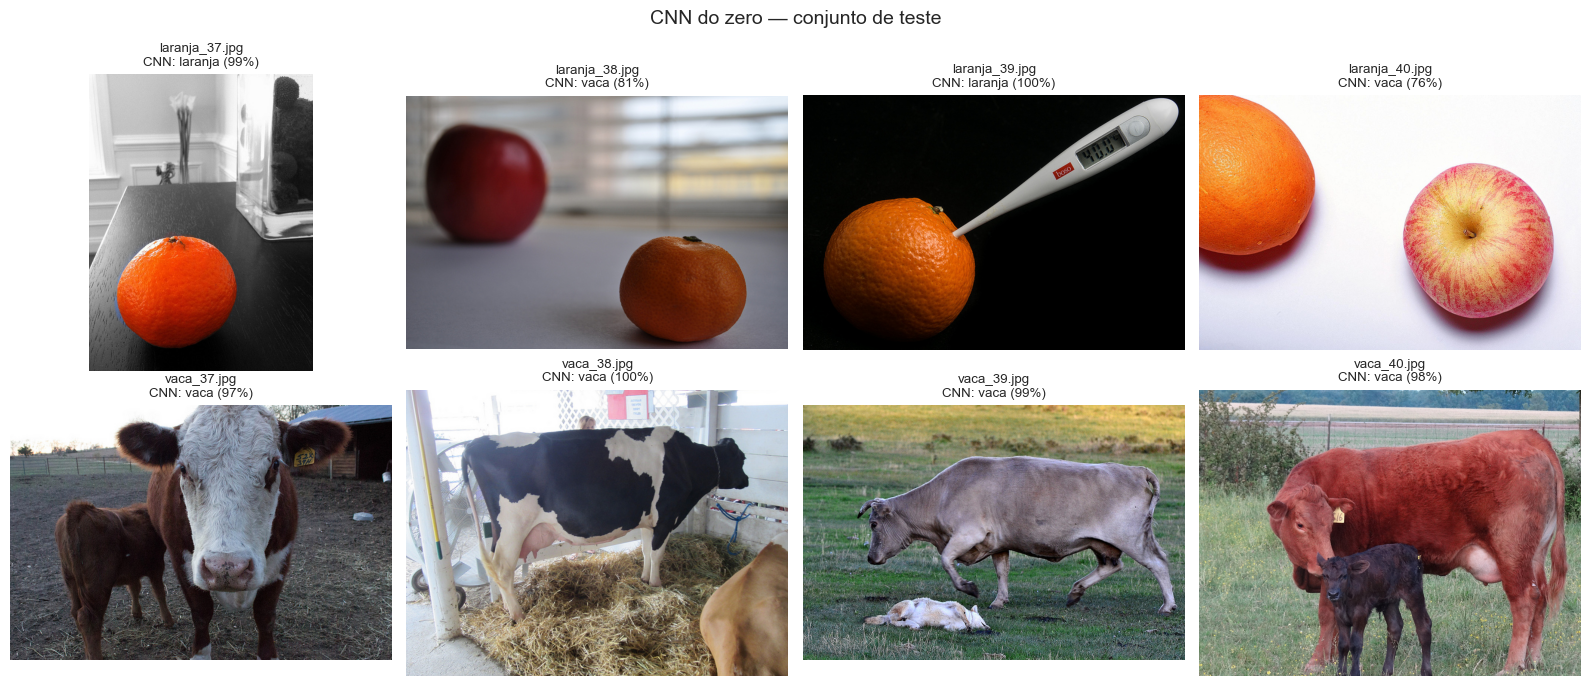

In [31]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

prob_te = cnn.predict(X_te, verbose=0).ravel()                # probabilidade de laranja
pred_te = (prob_te > 0.5).astype(int)
print('Acurácia da CNN no teste:', accuracy_score(y_te, pred_te))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred_te), display_labels=CLASSES).plot(cmap='Blues'); plt.show()

fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, img, p in zip(axs.flat, cam_te, prob_te):
    classe = CLASSES[int(p > 0.5)]
    conf = p if p > 0.5 else 1 - p
    ax.imshow(Image.open(img)); ax.set_title(f'{img.name}\nCNN: {classe} ({conf:.0%})'); ax.axis('off')
fig.suptitle('CNN do zero — conjunto de teste', fontsize=14); plt.tight_layout(); plt.show()

## 7. Entrega 2 — Comparação das três abordagens

Para comparar detectores e um classificador na mesma régua, transformamos a saída do YOLO em uma classificação da imagem:
**a classe da detecção de maior confiança** (se não houver detecção, conta como erro). Assim calculamos a **acurácia por imagem**
das três abordagens nas mesmas 8 imagens de teste.

O tempo de inferência é medido da mesma forma para todas: leitura da imagem do disco até a resposta, uma imagem por vez,
após uma execução de aquecimento.

In [32]:
def classificar_yolo(pesos, mapa_ids, classes_filtro=None):
    """Classifica cada imagem de teste pela detecção de maior confiança. Devolve (predições, ms por imagem)."""
    modelo = torch.hub.load(str(YOLO_DIR), 'custom', path=str(pesos), source='local', verbose=False)
    modelo.classes = classes_filtro                            # restringe às classes de interesse (YOLO tradicional)
    modelo(str(cam_te[0]))                                     # aquecimento
    preds, tempos = [], []
    for img in cam_te:
        t0 = time.perf_counter()
        det = modelo(str(img)).pandas().xyxy[0]                # caixas detectadas
        tempos.append(time.perf_counter() - t0)
        det = det[det['class'].isin(mapa_ids)]
        preds.append(mapa_ids[det.sort_values('confidence').iloc[-1]['class']] if len(det) else -1)  # -1 = nada detectado
    return np.array(preds), 1000 * np.mean(tempos)

def classificar_cnn():
    """Mesma medição para a CNN: lê, redimensiona e classifica uma imagem por vez."""
    ler = lambda p: np.asarray(Image.open(p).convert('RGB').resize((TAM, TAM)), dtype='float32')[None]
    cnn(ler(cam_te[0]), training=False)                        # aquecimento
    preds, tempos = [], []
    for img in cam_te:
        t0 = time.perf_counter()
        preds.append(int(cnn(ler(img), training=False).numpy()[0, 0] > 0.5))
        tempos.append(time.perf_counter() - t0)
    return np.array(preds), 1000 * np.mean(tempos)

resultados = {
    'YOLO custom 30 ép.': classificar_yolo(RUNS / 'train' / 'e30' / 'weights' / 'best.pt', {0: 0, 1: 1}),
    'YOLO custom 60 ép.': classificar_yolo(RUNS / 'train' / 'e60' / 'weights' / 'best.pt', {0: 0, 1: 1}),
    'YOLO tradicional (COCO)': classificar_yolo(PESOS_COCO, {19: 0, 49: 1}, classes_filtro=[19, 49]),
    'CNN do zero': classificar_cnn(),
}

# Predição de cada abordagem por imagem de teste
pd.DataFrame({nome: [CLASSES[p] if p >= 0 else 'nenhuma' for p in preds] for nome, (preds, _) in resultados.items()},
             index=[p.name for p in cam_te])

YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


,YOLO custom 30 ép.,YOLO custom 60 ép.,YOLO tradicional (COCO),CNN do zero
laranja_37.jpg,laranja,laranja,laranja,laranja
laranja_38.jpg,laranja,laranja,laranja,vaca
laranja_39.jpg,laranja,laranja,laranja,laranja
laranja_40.jpg,laranja,laranja,laranja,vaca
vaca_37.jpg,vaca,vaca,vaca,vaca
vaca_38.jpg,vaca,vaca,vaca,vaca
vaca_39.jpg,vaca,vaca,vaca,vaca
vaca_40.jpg,vaca,vaca,vaca,vaca


In [33]:
# Tabela final da comparação
det_teste = {**{k[0]: v for k, v in metricas_custom.items() if k[1] == 'test'}, **{k[0]: v for k, v in metricas_coco.items()}}
facilidade = {
    'YOLO custom 30 ép.': 'Média: exige rotular caixas e treinar com GPU',
    'YOLO custom 60 ép.': 'Média: exige rotular caixas e treinar com GPU',
    'YOLO tradicional (COCO)': 'Alta: pronto para uso, sem rotulação nem treino',
    'CNN do zero': 'Média: rótulo só por pasta/nome, mas a arquitetura é definida e ajustada à mão',
}
treino = {'YOLO custom 30 ép.': tempo_treino[30], 'YOLO custom 60 ép.': tempo_treino[60],
          'YOLO tradicional (COCO)': 0.0, 'CNN do zero': tempo_treino['CNN']}

comparacao = pd.DataFrame({
    nome: {
        'facilidade de uso': facilidade[nome],
        'acurácia por imagem (teste)': accuracy_score(y_te, preds),
        'mAP@0.5 (teste)': det_teste.get(nome, {}).get('mAP@0.5', np.nan),
        'precisão det. (teste)': det_teste.get(nome, {}).get('precisão', np.nan),
        'recall det. (teste)': det_teste.get(nome, {}).get('recall', np.nan),
        'tempo de treino (s)': treino[nome],
        'inferência (ms/img)': ms,
    } for nome, (preds, ms) in resultados.items()
}).T
comparacao.round(3)

,facilidade de uso,acurácia por imagem (teste),mAP@0.5 (teste),precisão det. (teste),recall det. (teste),tempo de treino (s),inferência (ms/img)
YOLO custom 30 ép.,Média: exige rotular caixas e treinar com GPU,1.0,0.922857,0.685656,0.962958,145.354022,19.670135
YOLO custom 60 ép.,Média: exige rotular caixas e treinar com GPU,1.0,0.8775,0.687771,1.0,188.850389,17.112049
YOLO tradicional (COCO),"Alta: pronto para uso, sem rotulação nem treino",1.0,0.935714,0.908939,1.0,0.0,19.023738
CNN do zero,"Média: rótulo só por pasta/nome, mas a arquite...",0.75,NaN,NaN,NaN,8.850313,17.419411


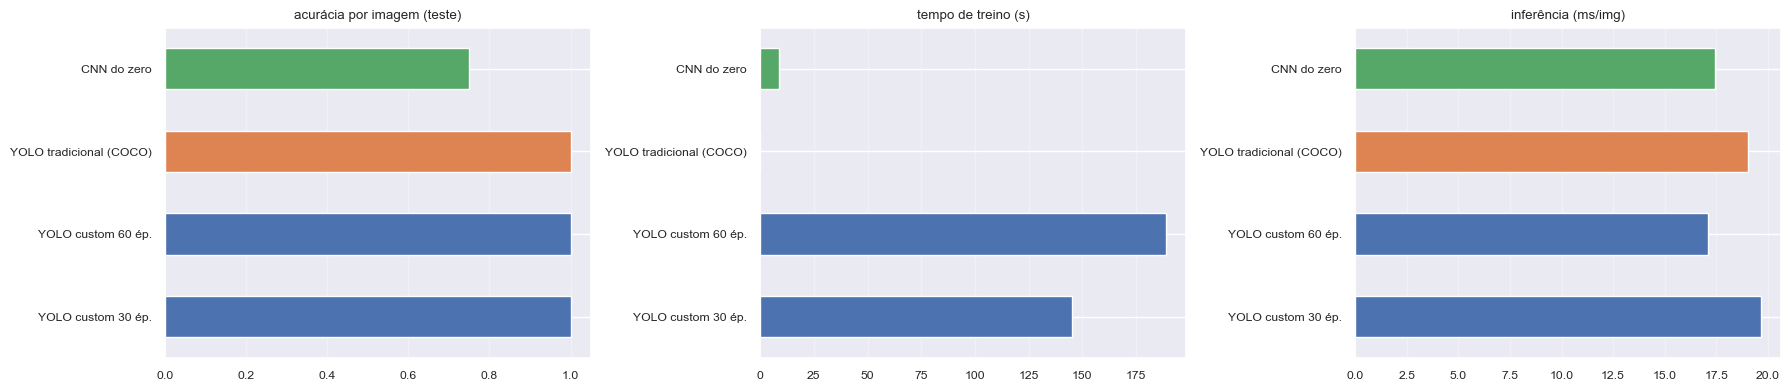

In [34]:
# Visualização dos números da comparação
fig, axs = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axs, ['acurácia por imagem (teste)', 'tempo de treino (s)', 'inferência (ms/img)']):
    comparacao[col].astype(float).plot.barh(ax=ax, color=['#4C72B0', '#4C72B0', '#DD8452', '#55A868'])
    ax.set_title(col); ax.grid(axis='x', alpha=.3)
plt.tight_layout(); plt.show()

### 7.1 Avaliação crítica

**Facilidade de uso / integração**
- **YOLO tradicional** é o mais fácil: não exige rotulação nem treino — duas linhas de código e o modelo já detecta vacas e laranjas.
  A limitação é que ele só conhece as 80 classes do COCO; para qualquer objeto fora dessa lista (uma praga específica, um equipamento da fazenda,
  uma raça de gado) ele simplesmente não serve.
- **YOLO customizado** dá mais trabalho no início (desenhar caixas em todas as imagens no Make Sense e treinar com GPU), mas depois o uso é
  idêntico ao do tradicional, e ele aprende **qualquer** classe que o cliente precisar.
- **CNN do zero** é simples de rotular (basta o nome do arquivo/pasta), mas exige projetar a arquitetura e ajustar hiperparâmetros na mão, e
  só responde "qual objeto é a imagem" — não diz **onde** ele está nem quantos existem.

**Precisão (teste, 8 imagens)**
- As três versões do YOLO acertaram **8 de 8** imagens. A CNN acertou **6 de 8 (75%)**: errou `laranja_38` e `laranja_40`, classificadas como vaca —
  justamente as duas fotos com maçã ao lado da laranja, que também geraram caixas erradas no YOLO.
- Na detecção, o YOLO tradicional teve o melhor resultado (precisão 0,91, mAP@0.5 0,94, mAP@0.5:0.95 0,87), à frente do customizado de 60 épocas
  (0,69 / 0,88 / 0,74).
- **Atenção:** esse resultado do YOLO tradicional é **otimista**. As 8 imagens de teste vieram do conjunto de treino do COCO (`train2017`), o
  mesmo usado para treinar os pesos `yolov5s.pt` — ou seja, ele provavelmente já viu essas fotos. Além disso, aprendeu com milhares de vacas
  e laranjas, contra as nossas 64 imagens. Para o modelo customizado, ao contrário, o teste é de fato inédito.
- A CNN do zero, com só 64 imagens de treino e ~24 mil parâmetros, aprendeu a separar as classes mas confunde laranjas em cenários menos
  típicos — é o efeito esperado de treinar uma rede do zero com tão poucos dados.

**Tempo de treinamento / customização**
- YOLO tradicional: **0 s** (já vem treinado).
- CNN do zero: **~9 s** (45 épocas até o *early stopping*), por ser uma rede minúscula com imagens de 128 px.
- YOLO customizado: **~145 s (30 épocas)** e **~189 s (60 épocas)** na GPU T4 — ainda assim, poucos minutos. O tempo de rotular as 80 imagens
  no Make Sense (bem maior que o de treino) também entra nessa conta.

**Tempo de inferência (por imagem, incluindo leitura do arquivo)**
- Todas ficaram entre **17 e 20 ms por imagem** na GPU T4 — as quatro rodariam em tempo real (50+ imagens por segundo). Só o modelo,
  sem a leitura do arquivo, o YOLOv5s leva ~5–6 ms por imagem (saída do `val.py` acima).
- Na prática há um **empate**: a CNN tem ~24 mil parâmetros contra ~7 milhões do YOLOv5s, mas em imagens isoladas o tempo é dominado por
  leitura e pré-processamento. Com só 8 imagens, diferenças de 1–3 ms são variação de medição.

**Resumo:** para objetos que já existem no COCO e quando só se quer uma demonstração rápida, o YOLO tradicional resolve sem custo. Para o
cenário real da FarmTech — classes próprias de cada cliente — o **YOLO customizado** é a melhor escolha: detecta e localiza com alta
acurácia depois de poucos minutos de treino. A CNN do zero é a opção mais leve, mas precisaria de muito mais imagens (ou de *transfer learning*)
para ter acurácia comparável, e não localiza os objetos.

## 8. Conclusões

**O que o projeto mostrou ao cliente da FarmTech**
- Com apenas **64 imagens rotuladas** e cerca de 3 minutos de treino em GPU, o YOLOv5 customizado reconheceu vacas e laranjas em **100% das
  imagens de teste**, com caixas bem posicionadas (mAP@0.5 de 0,88 a 0,92) e encontrando inclusive animais que não tinham sido rotulados.
- Mais épocas melhoraram a **qualidade da localização** (mAP@0.5:0.95 de 0,65 para 0,74 no teste) com pouco custo extra de treino.
- Entre as abordagens, o YOLO (customizado ou tradicional) superou a CNN treinada do zero, que acertou 75% das imagens.

**Pontos fortes**
- Pipeline completo e reprodutível: imagens organizadas no Drive, rotulação no Make Sense, treino, validação e teste no Colab.
- Comparação justa: as quatro abordagens foram avaliadas nas **mesmas imagens de teste**, com as mesmas métricas e o mesmo procedimento de medição de tempo.
- O *transfer learning* a partir do `yolov5s.pt` permitiu bons resultados mesmo com um dataset muito pequeno.

**Limitações**
- **Conjunto de teste muito pequeno** (8 imagens, 10 caixas): uma única caixa errada muda as métricas em vários pontos. As conclusões indicam
  tendências, não diferenças estatisticamente significativas.
- **Imagens vindas do COCO**: o YOLO tradicional provavelmente já viu as fotos de teste durante o seu treino, o que favorece esse modelo na comparação.
- As fotos são de bancos públicos, com objetos bem visíveis; câmeras reais de fazenda (ângulos ruins, baixa luz, objetos distantes) seriam mais difíceis.
- O dataset não tem exemplos negativos: os modelos confundem **maçãs com laranjas**.
- A CNN do zero foi treinada com pouquíssimas imagens e sem ajuste fino de hiperparâmetros.

**Próximos passos**
- Ampliar o dataset (centenas de imagens por classe), incluir imagens de outras frutas sem rótulo como exemplos negativos e montar um teste
  com **fotos próprias**, de fora do COCO.
- Testar com imagens de câmeras reais (ex.: ESP32-CAM) — proposta do "Ir Além" 1.
- Usar *transfer learning* (MobileNet, VGG) no lugar da CNN do zero — proposta do "Ir Além" 2.